# 🍌 Banana Ripeness — MobileNetV2 · Kaggle · Split thống nhất với nhóm

**Chỉ MobileNetV2**, gồm 3 thí nghiệm: **(1)** Frozen Backbone, **(2)** Fine-tuning, **(3)** Fine-tuning + Online Augmentation. Kèm **Feature Maps, Grad-CAM, RGB/Grayscale**, lưu checkpoint tốt nhất.

### Chuẩn bị (chỉ cần Add Input, không dán dữ liệu vào notebook)

1. Trong Kaggle chọn **Add Input** cho **dataset ảnh chuối** (ZIP hoặc thư mục ảnh) và **`manifest_used.csv`** của nhóm (có thể tạo Private Dataset chứa CSV). Nếu là 2 dataset Kaggle khác nhau, thêm cả hai.
2. **Accelerator → GPU**. Để tải trọng số ImageNet, bật Internet nếu tài khoản cho phép; nếu không, thêm weights `.pth` của *MobileNetV2 ImageNet* qua Add Input và khai báo `IMAGENET_WEIGHTS_FILE` ở cell cấu hình.
3. **Run All** → kết quả ở `/kaggle/working/banana_mobilenet_manifest_results.zip`. Dùng **Save Version** để lưu toàn bộ Output.

**Quan trọng:** Chương trình **không chia lại dữ liệu**. Chỉ sử dụng trực tiếp các cột `path, label, source_id, split, label_id` trong manifest. Ảnh tăng cường từ cùng `source_id` không được ở nhiều split. Nếu thiếu tệp ảnh hoặc manifest có vấn đề, notebook sẽ **dừng** và thông báo lỗi, không tự chia ngẫu nhiên.

## 1. Cấu hình, thư viện và đường dẫn Add Input

In [1]:
import os, json, random, zipfile, shutil, hashlib, time
from pathlib import Path, PurePosixPath
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import MobileNet_V2_Weights

# Hai input này sẽ tự được tìm trong /kaggle/input (có thể ghi đường dẫn tường minh nếu cần).
INPUT_ROOT = Path('/kaggle/input') if Path('/kaggle/input').exists() else Path('/mnt/data')
WORK_ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
MANIFEST_CSV = None                # Ví dụ: '/kaggle/input/banana-manifest/manifest_used.csv'
DATASET_SOURCE = None              # Ví dụ: '/kaggle/input/banana-data/augmented-banana.zip'
IMAGENET_WEIGHTS_FILE = None       # Để None khi Internet bật; nếu offline: trỏ tới .pth ImageNet 1000 lớp

SEED, IMG_SIZE, BATCH_SIZE, NUM_WORKERS = 42, 224, 32, 2
EPOCHS = {'MobileNet 1': 6, 'MobileNet 2': 10, 'MobileNet 3': 10}
PATIENCE, LAST_BLOCKS = 4, 4
HEAD_LR, FINETUNE_LR, WEIGHT_DECAY = 1e-3, 1e-4, 1e-4
GRADCAM_CORRECT, GRADCAM_WRONG, FEATURE_CHANNELS = 3, 3, 4

OUT = WORK_ROOT / 'banana_mobilenet_manifest_results'
for folder in (OUT, OUT/'checkpoints', OUT/'figures', OUT/'reports'):
    folder.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def fix_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
fix_seed()
print('Device:', DEVICE, '| Input:', INPUT_ROOT, '| Output:', OUT)

Device: cuda | Input: /kaggle/input | Output: /kaggle/working/banana_mobilenet_manifest_results


## 2. Đọc **đúng manifest của nhóm** và kiểm tra rò rỉ giữa các split

In [2]:
def find_manifest():
    if MANIFEST_CSV:
        p = Path(MANIFEST_CSV)
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    matches = sorted(INPUT_ROOT.rglob('manifest_used.csv'))
    if not matches:
        raise FileNotFoundError('Không thấy manifest_used.csv trong Add Input. Hãy thêm CSV vào Kaggle và Run All.')
    if len(matches) > 1:
        raise ValueError(f'Tìm thấy nhiều manifest_used.csv: {matches}. Hãy đặt MANIFEST_CSV tường minh.')
    return matches[0]

manifest_path = find_manifest()
manifest = pd.read_csv(manifest_path, dtype={'path':str,'label':str,'source_id':str,'split':str,'label_id':int})
required = {'path','label','source_id','split','label_id'}
if not required.issubset(manifest.columns): raise ValueError(f'Manifest thiếu cột: {required-set(manifest.columns)}')
if manifest[list(required)].isna().any().any(): raise ValueError('Manifest có giá trị trống trong các cột bắt buộc.')
manifest['split'] = manifest['split'].str.lower().str.strip().replace({'val':'valid','validation':'valid'})
if set(manifest['split']) != {'train','valid','test'}:
    raise ValueError(f'Các split phải có train, valid, test. Hiện có: {manifest.split.unique().tolist()}')
if manifest.path.duplicated().any(): raise ValueError('Manifest có path trùng lặp.')
if manifest.groupby('source_id')['split'].nunique().gt(1).any():
    raise ValueError('DATA LEAKAGE: Cùng source_id xuất hiện ở nhiều split. Dừng để sửa manifest nhóm.')
if manifest.groupby('source_id')['label'].nunique().gt(1).any():
    raise ValueError('Cùng source_id có nhiều nhãn khác nhau.')
pairs = manifest[['label','label_id']].drop_duplicates().sort_values('label_id')
if pairs.label.duplicated().any() or pairs.label_id.duplicated().any():
    raise ValueError('label và label_id không tạo ánh xạ 1-1.')
if pairs.label_id.tolist() != list(range(len(pairs))):
    raise ValueError('label_id phải liên tục từ 0 đến số lớp - 1; không tự đổi ID của nhóm.')
class_names = pairs.label.tolist(); NUM_CLASSES = len(class_names)
if NUM_CLASSES < 2: raise ValueError('Cần ít nhất 2 lớp.')
class_to_idx = dict(zip(pairs.label,pairs.label_id))
if any(PurePosixPath(p.replace('\\','/')).is_absolute() or '..' in PurePosixPath(p.replace('\\','/')).parts for p in manifest.path):
    raise ValueError('Manifest có đường dẫn tuyệt đối hoặc ../ không an toàn.')
manifest['path'] = manifest.path.str.replace('\\','/',regex=False)
if not all(PurePosixPath(p).parts[-2] == label for p,label in zip(manifest.path,manifest.label)):
    raise ValueError('Thư mục nhãn trong path không nhất quán với cột label.')
manifest['source_id'] = manifest['source_id'].astype(str)

split_counts = manifest.groupby('split').size().reindex(['train','valid','test'])
print('Manifest:',manifest_path)
print('SHA256:',hashlib.sha256(manifest_path.read_bytes()).hexdigest())
print('Nhãn / ID:',class_to_idx,'| Tổng ảnh:',len(manifest),'| Số source_id:',manifest.source_id.nunique())
print('Kiểm tra source_id giao giữa các split: 0 (ĐẠT)')
display(pd.crosstab(manifest['label'],manifest['split']).reindex(class_names))
print('Số ảnh theo split:',split_counts.to_dict())
shutil.copy2(manifest_path, OUT/'manifest_used.csv')

Manifest: /kaggle/input/datasets/thinhng04/banana-dataset/manifest_used.csv
SHA256: 2ea3def7e0fdc7718abd7dde904c0946ddd205ef6e0a67f86090337596e5f176
Nhãn / ID: {'Green': 0, 'Semi-ripe': 1, 'Ripe': 2, 'Overripe': 3} | Tổng ảnh: 2457 | Số source_id: 819
Kiểm tra source_id giao giữa các split: 0 (ĐẠT)


split,test,train,valid
label,,,
Green,99,444,93
Semi-ripe,93,426,90
Ripe,93,420,90
Overripe,93,426,90


Số ảnh theo split: {'train': 1716, 'valid': 363, 'test': 378}


PosixPath('/kaggle/working/banana_mobilenet_manifest_results/manifest_used.csv')

## 3. Xác định ảnh từ Add Input (thư mục hoặc ZIP) — thiếu ảnh sẽ dừng

Ảnh đọc từ: /kaggle/input/datasets/thinhng04/banana-dataset/Augmented Banana Ripeness Detection Dataset/Augmented Banana Ripeness Detection Dataset | Input: extracted folder
Khớp manifest: 2457 / 2457 ảnh


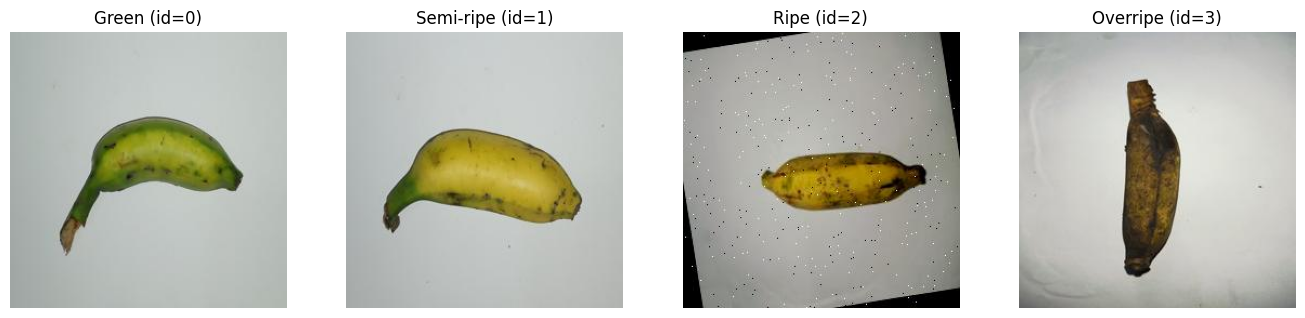

In [3]:
IMAGE_EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.webp'}
probe = [PurePosixPath(p) for p in manifest.path.iloc[np.linspace(0,len(manifest)-1,min(10,len(manifest)),dtype=int)]]

def locate_root(folder):
    # Giả sử đường dẫn trong manifest là Class/Filename. ZIP có thể có nhiều thư mục cha.
    candidates = set()
    for x in folder.rglob(probe[0].name):
        if x.is_file() and x.parent.name == probe[0].parts[0]:
            candidates.add(x.parent.parent)
    if not candidates: return None
    return max(candidates,key=lambda root:sum((root/str(p)).is_file() for p in probe))

def zip_matches_manifest(zpath):
    try:
        with zipfile.ZipFile(zpath) as z:
            names = z.namelist()
            return sum(any(n.replace('\\','/').endswith('/'+str(p)) or n.replace('\\','/') == str(p) for n in names) for p in probe)
    except (OSError,zipfile.BadZipFile): return 0

def find_data_root():
    src = Path(DATASET_SOURCE) if DATASET_SOURCE else INPUT_ROOT
    if not src.exists(): raise FileNotFoundError(f'DATASET_SOURCE không tồn tại: {src}')
    if src.is_dir():
        root = locate_root(src)
        if root and sum((root/str(p)).exists() for p in probe) == len(probe):
            return root, 'extracted folder'
        zips = list(src.rglob('*.zip'))
    else:
        zips = [src] if src.suffix.lower()=='.zip' else []
    scored = sorted(((zip_matches_manifest(z),z) for z in zips),reverse=True)
    if not scored or scored[0][0] < len(probe):
        raise FileNotFoundError('Không thấy bộ ảnh khớp manifest trong Add Input. Kiểm tra đúng ZIP augmented banana ripeness và MANIFEST_CSV.')
    zip_file = scored[0][1]
    extraction = WORK_ROOT / 'banana_manifest_images'
    extraction.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(zip_file) as archive:
        for info in archive.infolist():
            p = PurePosixPath(info.filename.replace('\\','/'))
            if p.is_absolute() or '..' in p.parts:
                raise ValueError(f'ZIP chứa đường dẫn không an toàn: {info.filename}')
        print('Đang giải nén ZIP phù hợp:',zip_file)
        archive.extractall(extraction)
    root = locate_root(extraction)
    if root is None: raise FileNotFoundError('Đã giải nén nhưng không tìm thấy ảnh theo manifest.')
    return root,str(zip_file)

DATA_ROOT, DATA_ORIGIN = find_data_root()
manifest['image_path'] = manifest.path.map(lambda p:str(DATA_ROOT/p))
missing = manifest.loc[~manifest.image_path.map(lambda x:Path(x).is_file()),'path']
if len(missing):
    raise FileNotFoundError(f'Thiếu {len(missing)}/{len(manifest)} ảnh trong dataset. Ví dụ: {missing.head(8).tolist()}')
print('Ảnh đọc từ:',DATA_ROOT,'| Input:',DATA_ORIGIN)
print('Khớp manifest:',len(manifest),'/',len(manifest),'ảnh')

train_df = manifest[manifest.split=='train'].reset_index(drop=True)
valid_df = manifest[manifest.split=='valid'].reset_index(drop=True)
test_df = manifest[manifest.split=='test'].reset_index(drop=True)
for s,frame in [('train',train_df),('valid',valid_df),('test',test_df)]:
    if set(frame.label_id) != set(range(NUM_CLASSES)):
        raise ValueError(f'Split {s} thiếu lớp. Không thể đánh giá công bằng.')
fig,axs = plt.subplots(1,NUM_CLASSES,figsize=(3.4*NUM_CLASSES,3.2),squeeze=False)
for i,label in enumerate(class_names):
    path = manifest.loc[manifest.label==label,'image_path'].iloc[0]
    with Image.open(path) as im: axs[0,i].imshow(im.convert('RGB'))
    axs[0,i].set_title(f'{label} (id={i})'); axs[0,i].axis('off')
fig.tight_layout(); fig.savefig(OUT/'figures'/'01_samples.png',dpi=140); plt.show()

## 4. DataLoader và chuẩn hóa đầu vào

- Mọi thí nghiệm dùng **cùng train/valid/test của nhóm**.
- Online Augmentation chỉ được thực hiện ở **MobileNet 3 / tập train**. Bộ dữ liệu có thể đã là ảnh augmented: ở đây chỉ thêm biến đổi nhẹ tại thời điểm huấn luyện.
- Đánh giá dùng ảnh RGB chuẩn hóa như nhau, không augmentation.

In [4]:
NORMALIZE = transforms.Normalize([.485,.456,.406],[.229,.224,.225])
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE,IMG_SIZE)),transforms.ToTensor(),NORMALIZE])
train_aug_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(12),transforms.ColorJitter(brightness=.08,contrast=.08,saturation=.05),
    transforms.ToTensor(),NORMALIZE
])
gray_tf = transforms.Compose([transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),transforms.ToTensor(),NORMALIZE])

class BananaDataset(Dataset):
    def __init__(self,frame,tf): self.rows=frame.reset_index(drop=True); self.tf=tf
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        row=self.rows.iloc[i]
        with Image.open(row.image_path) as im: x=self.tf(im.convert('RGB'))
        return x,int(row.label_id)

def make_loader(frame,tf,shuffle=False):
    return DataLoader(BananaDataset(frame,tf),batch_size=BATCH_SIZE,shuffle=shuffle,
                      num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))

valid_loader=make_loader(valid_df,eval_tf)
test_loader=make_loader(test_df,eval_tf)

## 5. MobileNetV2: Transfer Learning, checkpoint và đánh giá

In [5]:
def pretrained_model():
    if IMAGENET_WEIGHTS_FILE:
        model=models.mobilenet_v2(weights=None)
        state=torch.load(IMAGENET_WEIGHTS_FILE,map_location='cpu',weights_only=True)
        if isinstance(state,dict) and 'state_dict' in state: state=state['state_dict']
        if isinstance(state,dict) and 'model_state_dict' in state: state=state['model_state_dict']
        model.load_state_dict(state,strict=True)
    else:
        try: model=models.mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
        except Exception as exc:
            raise RuntimeError('Không tải được ImageNet pretrained. Bật Internet hoặc Add Input weights .pth và đặt IMAGENET_WEIGHTS_FILE.') from exc
    model.classifier[1]=nn.Linear(model.classifier[1].in_features,NUM_CLASSES)
    return model.to(DEVICE)

def load_checkpoint(path):
    ckpt=torch.load(path,map_location='cpu',weights_only=False)
    model=models.mobilenet_v2(weights=None)
    model.classifier[1]=nn.Linear(model.classifier[1].in_features,len(ckpt['class_names']))
    model.load_state_dict(ckpt['model_state_dict'])
    return model.to(DEVICE),ckpt

def configure_trainable(model,head_only):
    for p in model.features.parameters(): p.requires_grad=False
    if not head_only:
        for block in list(model.features.children())[-LAST_BLOCKS:]:
            for p in block.parameters(): p.requires_grad=True
    for p in model.classifier.parameters(): p.requires_grad=True

def freeze_bn_in_frozen_blocks(model,head_only):
    if head_only: model.features.eval()
    else:
        for block in list(model.features.children())[:-LAST_BLOCKS]: block.eval()

def run_epoch(model,loader,criterion,optimizer=None,scaler=None,head_only=False):
    training=optimizer is not None
    model.train(training)
    if training: freeze_bn_in_frozen_blocks(model,head_only)
    total_loss,total_n=0.,0
    truth,pred=[],[]
    for x,y in loader:
        x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
                logits=model(x); loss=criterion(logits,y)
            if training:
                scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
        total_loss+=loss.item()*len(y);total_n+=len(y)
        truth.extend(y.detach().cpu().tolist());pred.extend(logits.argmax(1).detach().cpu().tolist())
    return dict(loss=total_loss/total_n,accuracy=accuracy_score(truth,pred),
                f1_macro=f1_score(truth,pred,labels=list(range(NUM_CLASSES)),average='macro',zero_division=0),
                true=np.array(truth),pred=np.array(pred))

def train_experiment(name,model,head_only,augmentation,lr):
    fix_seed();configure_trainable(model,head_only)
    train_loader=make_loader(train_df,train_aug_tf if augmentation else eval_tf,shuffle=True)
    parameters=[p for p in model.parameters() if p.requires_grad]
    optimizer=torch.optim.AdamW(parameters,lr=lr,weight_decay=WEIGHT_DECAY)
    criterion=nn.CrossEntropyLoss()
    scaler=torch.amp.GradScaler('cuda',enabled=(DEVICE.type=='cuda'))
    ckpt_path=OUT/'checkpoints'/f'{name.lower().replace(" ","_")}_best.pth'
    best=-1.;best_epoch=0;stale=0;history=[]
    started=time.perf_counter()
    for ep in range(1,EPOCHS[name]+1):
        tr=run_epoch(model,train_loader,criterion,optimizer,scaler,head_only)
        va=run_epoch(model,valid_loader,criterion)
        history.append(dict(epoch=ep,train_loss=tr['loss'],valid_loss=va['loss'],
                train_accuracy=tr['accuracy'],valid_accuracy=va['accuracy'],
                train_f1=tr['f1_macro'],valid_f1=va['f1_macro']))
        print(f'{name} {ep:02d}/{EPOCHS[name]} | train acc {tr["accuracy"]:.3f} | '
              f'valid acc {va["accuracy"]:.3f} | valid F1 {va["f1_macro"]:.3f}')
        if va['f1_macro']>best+1e-6:
            best=float(va['f1_macro']);best_epoch=ep;stale=0
            torch.save({'arch':'mobilenet_v2','experiment':name,'epoch':ep,'class_names':class_names,
                        'class_to_idx':class_to_idx,'model_state_dict':model.state_dict(),
                        'best_val_f1_macro':best,'best_val_accuracy':float(va['accuracy']),
                        'img_size':IMG_SIZE,'seed':SEED,'manifest_sha256':MANIFEST_SHA},ckpt_path)
        else: stale+=1
        if stale>=PATIENCE: print('Early stopping.');break
    duration=time.perf_counter()-started
    hist=pd.DataFrame(history)
    hist.to_csv(OUT/'reports'/f'{name.replace(" ","_").lower()}_history.csv',index=False)
    model,ckpt=load_checkpoint(ckpt_path)
    te=run_epoch(model,test_loader,criterion)  # Chỉ báo cáo, không chọn checkpoint qua test.
    label_ids=list(range(NUM_CLASSES))
    report=classification_report(te['true'],te['pred'],labels=label_ids,target_names=class_names,zero_division=0)
    (OUT/'reports'/f'{name.replace(" ","_").lower()}_classification.txt').write_text(report,encoding='utf-8')
    predictions=test_df[['path','label','source_id','split','label_id']].copy()
    predictions['predicted_id']=te['pred'];predictions['predicted_label']=[class_names[i] for i in te['pred']]
    predictions.to_csv(OUT/'reports'/f'{name.replace(" ","_").lower()}_predictions.csv',index=False)
    return dict(experiment=name,strategy=('Frozen' if head_only else 'Fine-tune + Aug' if augmentation else 'Fine-tune'),
        best_epoch=best_epoch,trainable_parameters=sum(p.numel() for p in parameters),
        valid_accuracy=ckpt['best_val_accuracy'],valid_f1_macro=best,
        test_accuracy=te['accuracy'],test_f1_macro=te['f1_macro'],train_seconds=duration,
        checkpoint=str(ckpt_path)),hist,te

MANIFEST_SHA=hashlib.sha256(manifest_path.read_bytes()).hexdigest()

## 6. Chạy 3 thí nghiệm

MobileNet 2 và 3 **cùng khởi tạo từ checkpoint tốt nhất của MobileNet 1** để phân tích riêng ảnh hưởng của Fine-tuning và Augmentation. Không dùng test để chọn checkpoint.

In [6]:
results,histories,predictions={},{},{}
model1=pretrained_model()
results['MobileNet 1'],histories['MobileNet 1'],predictions['MobileNet 1']=train_experiment(
    'MobileNet 1',model1,head_only=True,augmentation=False,lr=HEAD_LR)
del model1
for name,aug in [('MobileNet 2',False),('MobileNet 3',True)]:
    model,_=load_checkpoint(results['MobileNet 1']['checkpoint'])
    results[name],histories[name],predictions[name]=train_experiment(
        name,model,head_only=False,augmentation=aug,lr=FINETUNE_LR)
    del model
    if DEVICE.type=='cuda': torch.cuda.empty_cache()

comparison=pd.DataFrame(list(results.values()))
comparison.to_csv(OUT/'mobilenet_comparison.csv',index=False)
print('BẢNG SO SÁNH 3 THÍ NGHIỆM — thống nhất manifest_used.csv')
display(comparison[['experiment','strategy','best_epoch','trainable_parameters','valid_accuracy','valid_f1_macro','test_accuracy','test_f1_macro','train_seconds']].round(4))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 231MB/s]


MobileNet 1 01/6 | train acc 0.772 | valid acc 0.876 | valid F1 0.878
MobileNet 1 02/6 | train acc 0.902 | valid acc 0.887 | valid F1 0.888
MobileNet 1 03/6 | train acc 0.918 | valid acc 0.893 | valid F1 0.893
MobileNet 1 04/6 | train acc 0.930 | valid acc 0.893 | valid F1 0.893
MobileNet 1 05/6 | train acc 0.936 | valid acc 0.904 | valid F1 0.904
MobileNet 1 06/6 | train acc 0.948 | valid acc 0.909 | valid F1 0.909
MobileNet 2 01/10 | train acc 0.893 | valid acc 0.912 | valid F1 0.910
MobileNet 2 02/10 | train acc 0.960 | valid acc 0.934 | valid F1 0.934
MobileNet 2 03/10 | train acc 0.974 | valid acc 0.923 | valid F1 0.922
MobileNet 2 04/10 | train acc 0.987 | valid acc 0.931 | valid F1 0.931
MobileNet 2 05/10 | train acc 0.994 | valid acc 0.915 | valid F1 0.915
MobileNet 2 06/10 | train acc 0.983 | valid acc 0.920 | valid F1 0.920
Early stopping.
MobileNet 3 01/10 | train acc 0.869 | valid acc 0.876 | valid F1 0.878
MobileNet 3 02/10 | train acc 0.942 | valid acc 0.917 | valid F1 0.

,experiment,strategy,best_epoch,trainable_parameters,valid_accuracy,valid_f1_macro,test_accuracy,test_f1_macro,train_seconds
0,MobileNet 1,Frozen,6,5124,0.9091,0.9093,0.9312,0.9305,80.5804
1,MobileNet 2,Fine-tune,2,1531204,0.9339,0.9339,0.9444,0.9439,30.9438
2,MobileNet 3,Fine-tune + Aug,7,1531204,0.9394,0.9396,0.9471,0.9465,67.1417


## 7. Biểu đồ Accuracy / Loss / F1, chọn best checkpoint bằng Validation

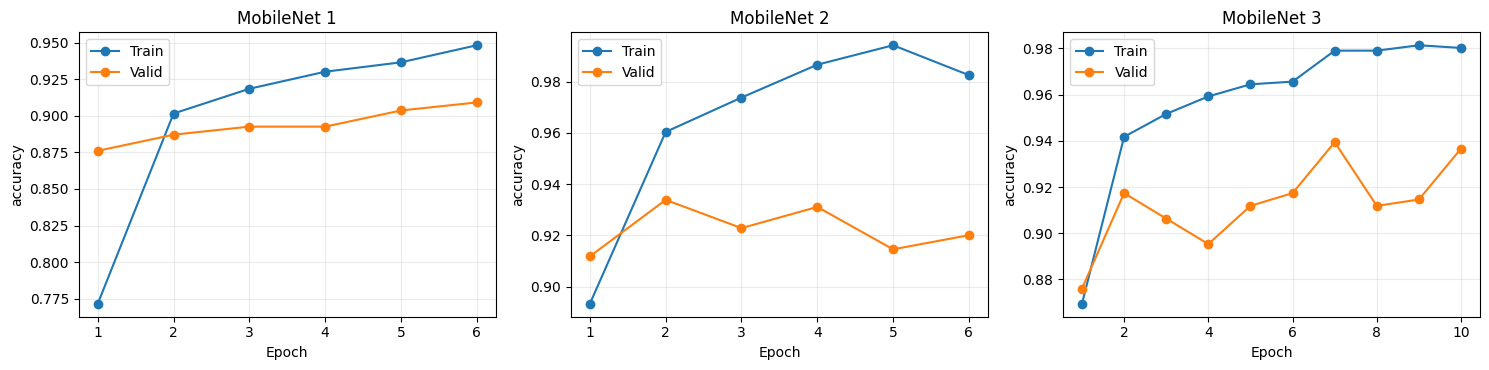

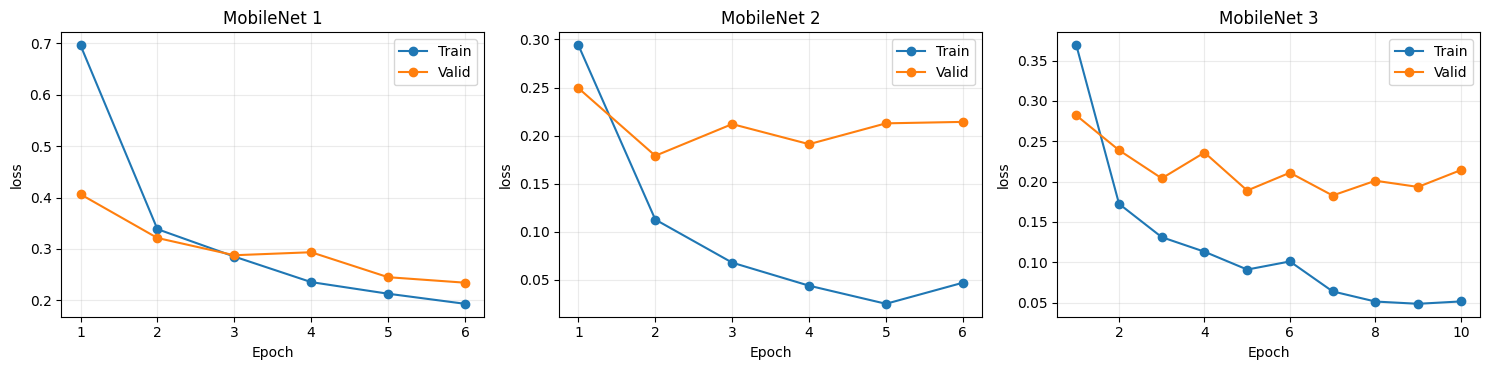

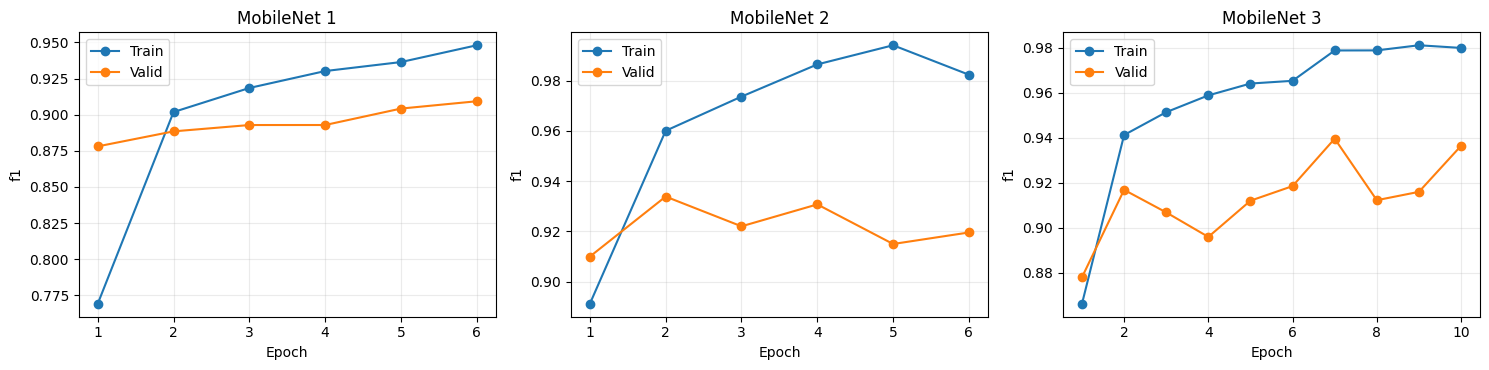

Best by Validation F1-Macro: MobileNet 3 | /kaggle/working/banana_mobilenet_manifest_results/checkpoints/mobilenetv2_best_overall.pth
Classification report TEST:
               precision    recall  f1-score   support

       Green       1.00      1.00      1.00        99
   Semi-ripe       0.89      0.95      0.92        93
        Ripe       0.92      0.94      0.93        93
    Overripe       0.99      0.90      0.94        93

    accuracy                           0.95       378
   macro avg       0.95      0.95      0.95       378
weighted avg       0.95      0.95      0.95       378



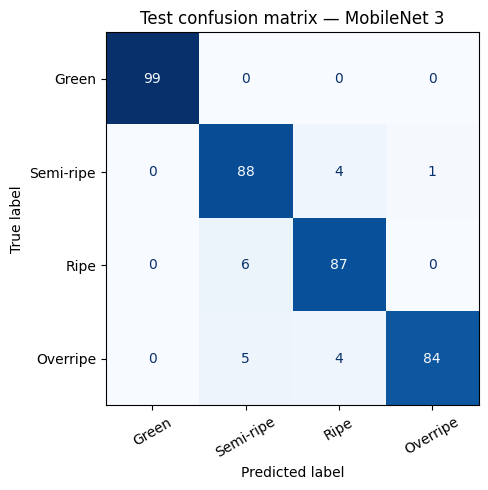

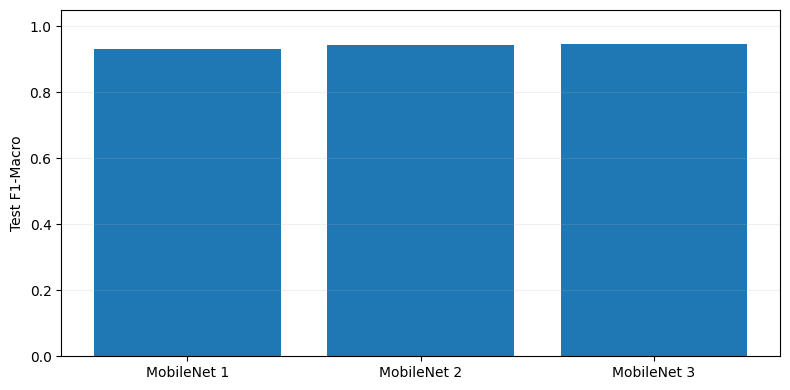

In [7]:
for metric in ['accuracy','loss','f1']:
    fig,axs=plt.subplots(1,3,figsize=(15,3.8))
    for ax,(name,hist) in zip(axs,histories.items()):
        ax.plot(hist.epoch,hist[f'train_{metric}'],'o-',label='Train')
        ax.plot(hist.epoch,hist[f'valid_{metric}'],'o-',label='Valid')
        ax.set_title(name);ax.set_xlabel('Epoch');ax.set_ylabel(metric);ax.grid(alpha=.25);ax.legend()
    fig.tight_layout();fig.savefig(OUT/'figures'/f'02_{metric}.png',dpi=150);plt.show()

best_name=comparison.sort_values(['valid_f1_macro','valid_accuracy'],ascending=False).iloc[0].experiment
best_path=OUT/'checkpoints'/'mobilenetv2_best_overall.pth'
shutil.copy2(results[best_name]['checkpoint'],best_path)
model,ckpt=load_checkpoint(best_path);model.eval()
print('Best by Validation F1-Macro:',best_name,'|',best_path)
print('Classification report TEST:\n',classification_report(predictions[best_name]['true'],
    predictions[best_name]['pred'],labels=range(NUM_CLASSES),target_names=class_names,zero_division=0))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(predictions[best_name]['true'],predictions[best_name]['pred'],
    labels=list(range(NUM_CLASSES)),display_labels=class_names,cmap='Blues',xticks_rotation=30,ax=ax,colorbar=False)
ax.set_title(f'Test confusion matrix — {best_name}')
fig.tight_layout();fig.savefig(OUT/'figures'/'03_confusion_matrix.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(8,4))
ax.bar(comparison.experiment,comparison.test_f1_macro)
ax.set_ylim(0,1.05);ax.set_ylabel('Test F1-Macro');ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'figures'/'04_test_f1_comparison.png',dpi=160);plt.show()

## 8. Feature Maps — xem các tầng backbone biểu diễn ảnh

Đọc **một ảnh test** và hiển thị các channel có phương sai kích hoạt cao ở tầng đầu, giữa và cuối. Đây là *activation maps*, không phải nhãn HSV/HOG/LBP có ý nghĩa cố định.

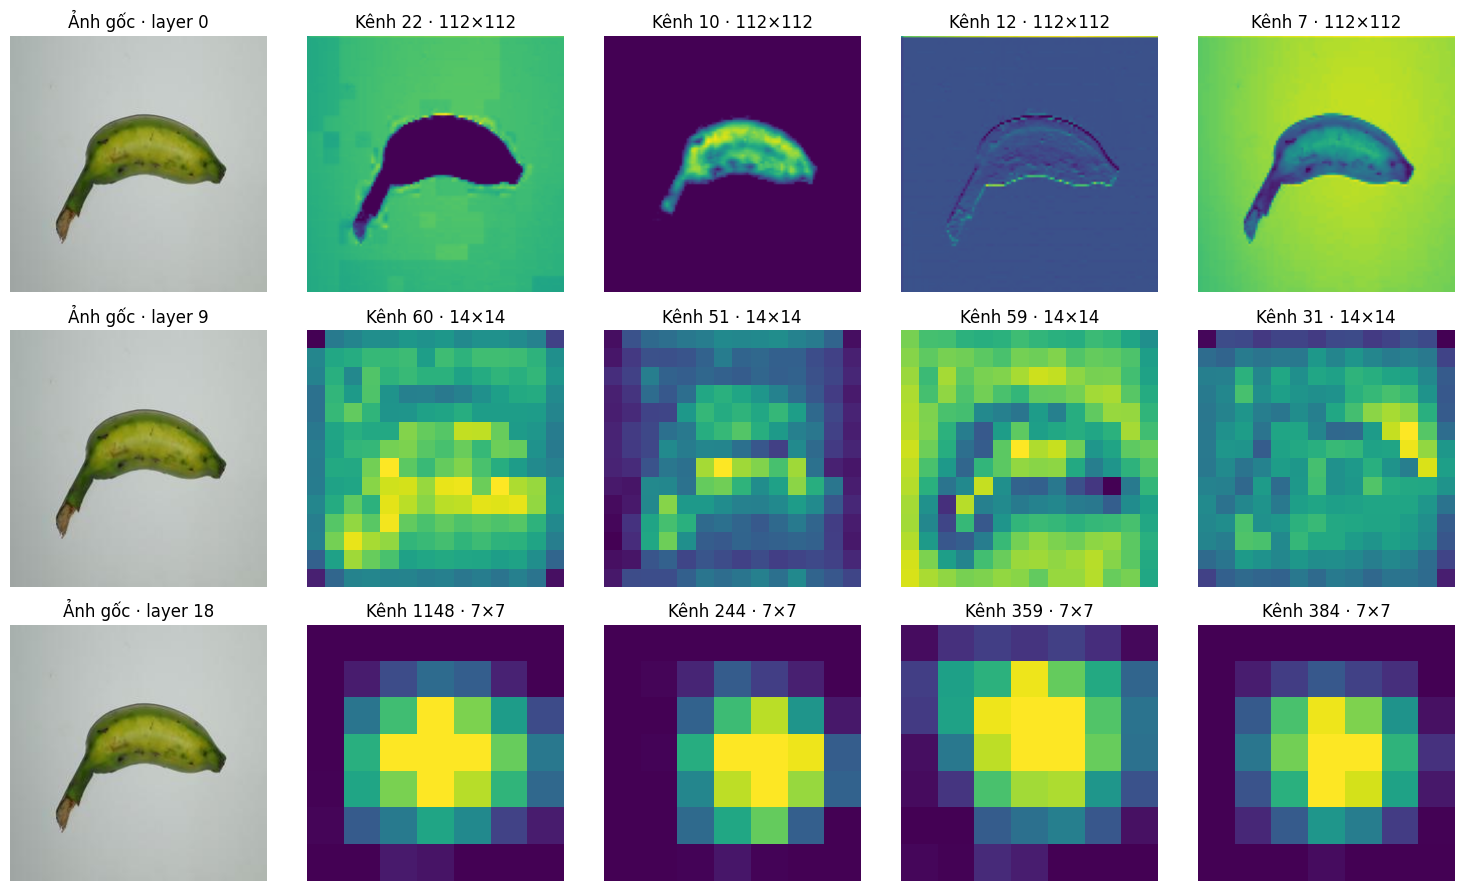

In [8]:
feature_image=test_df.iloc[0].image_path
layer_ids=sorted(set([0,len(model.features)//2,len(model.features)-1]))
feature_maps={};hooks=[]
for idx in layer_ids:
    hooks.append(model.features[idx].register_forward_hook(
        lambda module,inp,out,idx=idx:feature_maps.__setitem__(idx,out.detach().cpu())))
with Image.open(feature_image) as im: rgb=im.convert('RGB')
with torch.inference_mode(): _=model(eval_tf(rgb).unsqueeze(0).to(DEVICE))
for h in hooks: h.remove()
fig,axs=plt.subplots(len(layer_ids),FEATURE_CHANNELS+1,figsize=(3*(FEATURE_CHANNELS+1),3*len(layer_ids)),squeeze=False)
for r,idx in enumerate(layer_ids):
    f=feature_maps[idx][0].float().numpy()  # C,H,W
    chosen=np.argsort(f.reshape(f.shape[0],-1).var(1))[-FEATURE_CHANNELS:][::-1]
    axs[r,0].imshow(rgb);axs[r,0].set_title(f'Ảnh gốc · layer {idx}');axs[r,0].axis('off')
    for j,ch in enumerate(chosen,1):
        axs[r,j].imshow(f[ch],cmap='viridis');axs[r,j].set_title(f'Kênh {ch} · {f.shape[1]}×{f.shape[2]}');axs[r,j].axis('off')
fig.tight_layout();fig.savefig(OUT/'figures'/'05_feature_maps.png',dpi=160);plt.show()

## 9. Grad-CAM — mô hình tập trung vào đâu?

Chọn ảnh **dự đoán đúng và sai** từ tập test. Grad-CAM thể hiện vùng nhạy với logit của lớp dự đoán; đây là bằng chứng để phân tích chứ không khẳng định mô hình sử dụng HSV/HOG/LBP.

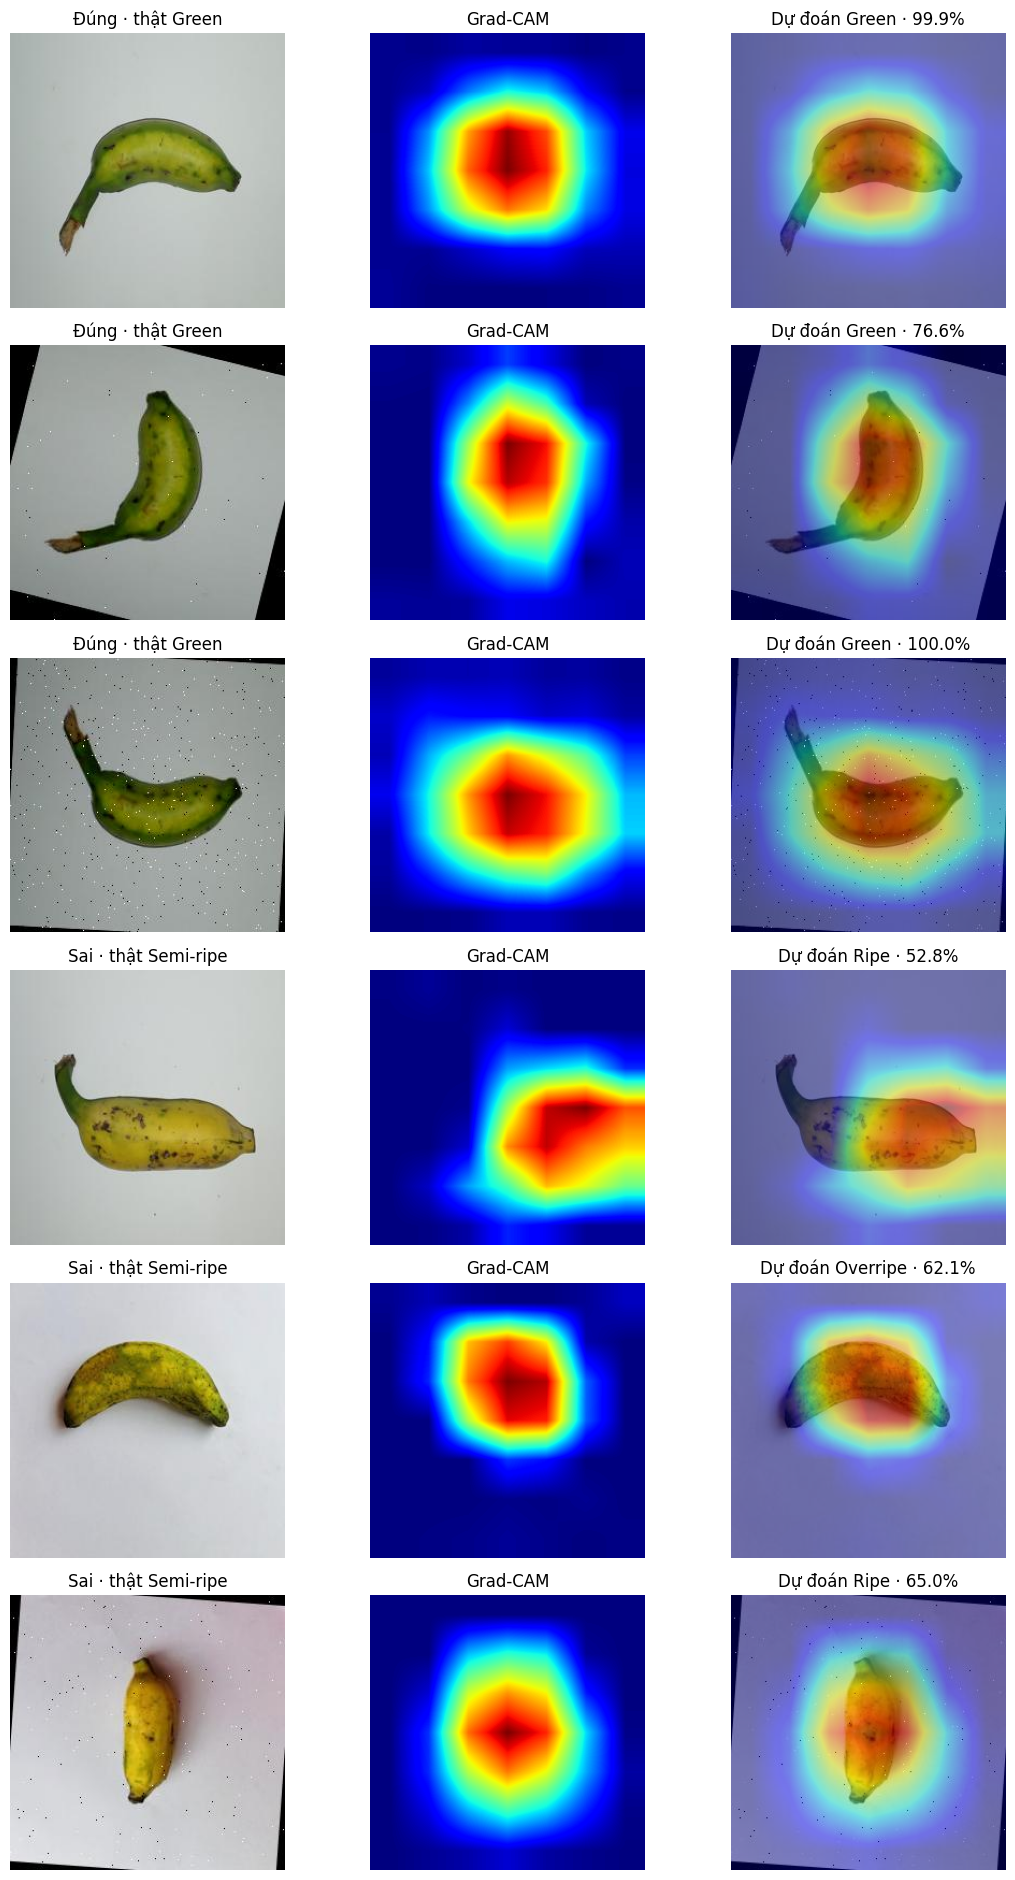

In [9]:
import torch.nn.functional as F

def gradcam_one(image_path):
    acts={}
    def capture(module,inp,out):
        acts['feat']=out
        out.register_hook(lambda g:acts.__setitem__('grad',g))
    handle=model.features[-1].register_forward_hook(capture)
    try:
        with Image.open(image_path) as im: original=im.convert('RGB')
        x=eval_tf(original).unsqueeze(0).to(DEVICE)
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logit=model(x); cls=int(logit.argmax(1).item())
            conf=float(logit.softmax(1)[0,cls].detach().cpu())
            logit[0,cls].backward()
        a=acts['feat'][0].detach().float();g=acts['grad'][0].detach().float()
        heat=F.relu((a*g.mean(dim=(1,2),keepdim=True)).sum(0))[None,None]
        heat=F.interpolate(heat,size=(original.height,original.width),mode='bilinear',align_corners=False)[0,0]
        heat=(heat-heat.min())/(heat.max()-heat.min()+1e-8)
        return original,heat.cpu().numpy(),cls,conf
    finally: handle.remove()

truth=predictions[best_name]['true'];pred=predictions[best_name]['pred']
chosen=[('Đúng',i) for i in np.flatnonzero(truth==pred)[:GRADCAM_CORRECT]]
chosen += [('Sai',i) for i in np.flatnonzero(truth!=pred)[:GRADCAM_WRONG]]
if not chosen: raise RuntimeError('Không có dự đoán test để vẽ Grad-CAM.')
fig,axs=plt.subplots(len(chosen),3,figsize=(11.5,3.15*len(chosen)),squeeze=False)
cam_rows=[]
for r,(state,i) in enumerate(chosen):
    row=test_df.iloc[i]
    original,heat,cl,conf=gradcam_one(row.image_path)
    overlay=np.clip(np.asarray(original)/255*.55+plt.get_cmap('jet')(heat)[...,:3]*.45,0,1)
    for ax,img,ttl in zip(axs[r],[original,heat,overlay],
                [f'{state} · thật {row.label}', 'Grad-CAM',f'Dự đoán {class_names[cl]} · {conf:.1%}']):
        ax.imshow(img,cmap='jet' if ttl=='Grad-CAM' else None);ax.set_title(ttl);ax.axis('off')
    cam_rows.append(dict(path=row.path,correct=(state=='Đúng'),true=row.label,pred=class_names[cl],confidence=conf))
fig.tight_layout();fig.savefig(OUT/'figures'/'06_gradcam.png',dpi=160);plt.show()
pd.DataFrame(cam_rows).to_csv(OUT/'reports'/'gradcam_examples.csv',index=False)

## 10. Ablation Study — RGB so với Grayscale (cùng checkpoint)

Giữ **nguyên test split, nhãn, weights và hyperparameters**, chỉ chuyển ảnh sang grayscale (3 kênh) để kiểm tra độ nhạy với việc loại bỏ màu sắc. Chênh lệch hiệu quả **không chứng minh** mạng dùng histogram HSV.

,input,test_accuracy,test_f1_macro
0,RGB,0.9471,0.9465
1,Grayscale 3 channels,0.4735,0.3964


Δ Gray - RGB Accuracy: -0.4735 | Δ F1-Macro: -0.5501


,class_name,rgb_f1,grayscale_f1,delta_f1
0,Green,1.0000,0.0392,-0.9608
1,Semi-ripe,0.9167,0.3846,-0.5321
2,Ripe,0.9255,0.5849,-0.3406
3,Overripe,0.9438,0.5769,-0.3669


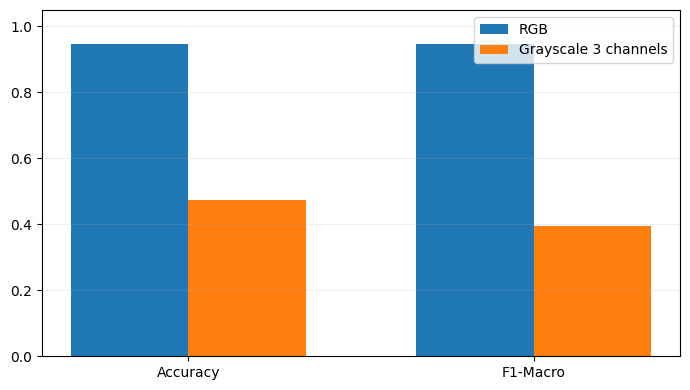

In [10]:
criterion=nn.CrossEntropyLoss()
rgb=run_epoch(model,test_loader,criterion)
gray=run_epoch(model,make_loader(test_df,gray_tf),criterion)
ablation=pd.DataFrame([
    {'input':'RGB','test_accuracy':rgb['accuracy'],'test_f1_macro':rgb['f1_macro']},
    {'input':'Grayscale 3 channels','test_accuracy':gray['accuracy'],'test_f1_macro':gray['f1_macro']}
])
ablation.to_csv(OUT/'reports'/'rgb_vs_grayscale.csv',index=False)
display(ablation.round(4))
print('Δ Gray - RGB Accuracy:',round(gray['accuracy']-rgb['accuracy'],4),
      '| Δ F1-Macro:',round(gray['f1_macro']-rgb['f1_macro'],4))
per_class=pd.DataFrame({'class_name':class_names,
    'rgb_f1':f1_score(rgb['true'],rgb['pred'],labels=range(NUM_CLASSES),average=None,zero_division=0),
    'grayscale_f1':f1_score(gray['true'],gray['pred'],labels=range(NUM_CLASSES),average=None,zero_division=0)})
per_class['delta_f1']=per_class.grayscale_f1-per_class.rgb_f1
per_class.to_csv(OUT/'reports'/'ablation_per_class.csv',index=False)
display(per_class.round(4))
fig,ax=plt.subplots(figsize=(7,4))
xx=np.arange(2);w=.34
for i,row in ablation.iterrows():
    ax.bar(xx+(i-.5)*w,[row.test_accuracy,row.test_f1_macro],width=w,label=row['input'])
ax.set_xticks(xx,['Accuracy','F1-Macro']);ax.set_ylim(0,1.05);ax.legend();ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'figures'/'07_rgb_grayscale.png',dpi=160);plt.show()

pd.DataFrame({'path':test_df.path,'true':test_df.label,'rgb_pred':[class_names[i] for i in rgb['pred']],
              'gray_pred':[class_names[i] for i in gray['pred']]}).to_csv(OUT/'reports'/'ablation_predictions.csv',index=False)

## 11. Lưu kết quả và ZIP để tải trên Kaggle Output

In [11]:
metadata={
    'manifest_file':str(manifest_path),'manifest_sha256':MANIFEST_SHA,
    'dataset_origin':str(DATA_ORIGIN),'num_images':len(manifest),'class_to_idx':class_to_idx,
    'source_id_split_overlap':0,'split_counts':split_counts.to_dict(),
    'seed':SEED,'image_size':IMG_SIZE,'epochs_config':EPOCHS,
    'best_experiment_by_valid_f1':best_name,'best_checkpoint':'checkpoints/mobilenetv2_best_overall.pth',
    'comparison':comparison.drop(columns='checkpoint').to_dict('records'),
    'note':'No random re-split. All images and labels follow manifest_used.csv.'
}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
(OUT/'README.txt').write_text(
    'Banana MobileNetV2 — use the group manifest_used.csv exactly.\n'
    'The best checkpoint is selected by validation F1-Macro (NOT test).\n'
    'See manifest_used.csv, run_metadata.json, mobilenet_comparison.csv, reports/, figures/, checkpoints/.\n',
    encoding='utf-8')
zip_out=WORK_ROOT/'banana_mobilenet_manifest_results.zip'
with zipfile.ZipFile(zip_out,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4) as z:
    for p in OUT.rglob('*'):
        if p.is_file(): z.write(p,arcname=str(Path(OUT.name)/p.relative_to(OUT)))
print('ĐÃ HOÀN THÀNH:',zip_out)
print('BEST CHECKPOINT:',best_path)
print('ẢNH:',len(manifest),'| train/valid/test:',*[len(x) for x in [train_df,valid_df,test_df]])
print('Toàn bộ dữ liệu vẫn tuân theo manifest của nhóm. Kết quả thực tế được tạo sau Run All.')

ĐÃ HOÀN THÀNH: /kaggle/working/banana_mobilenet_manifest_results.zip
BEST CHECKPOINT: /kaggle/working/banana_mobilenet_manifest_results/checkpoints/mobilenetv2_best_overall.pth
ẢNH: 2457 | train/valid/test: 1716 363 378
Toàn bộ dữ liệu vẫn tuân theo manifest của nhóm. Kết quả thực tế được tạo sau Run All.


### Lưu ý khi trình bày đồ án

- **MobileNetV2 cũng là CNN**, học đặc trưng qua các phép tích chập. Không cần khai báo thủ công HSV/HOG/LBP như khi dùng SVM.
- **MobileNet 1** kiểm tra đặc trưng ImageNet với backbone cố định; **MobileNet 2** điều chỉnh block cuối; **MobileNet 3** kiểm tra tác động của augmentation bổ sung trên train.
- Feature Maps giúp quan sát kích hoạt nội bộ; Grad-CAM hỗ trợ kiểm tra vùng ảnh ảnh hưởng đến quyết định; grayscale ablation cho thấy mức độ nhạy khi bỏ màu sắc. Không diễn giải chúng là bằng chứng xác định từng đặc trưng cụ thể.
- Không so sánh kết quả với thành viên khác nếu **manifest, tiền xử lý, thời điểm đánh giá hoặc seed** khác nhau. Không dùng test để tối ưu siêu tham số.